# Matrices
*Math foundations, part of my [Data Science Roadmap](../../README.md)*

**Goal:** Use small sales tables (days × [revenue, customers, units]) to practise matrix operations, and make sure **every multiplication means something**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  # for heatmaps

In [2]:
# Step 2.1: Create matrices (sales data)
# Rows = days, columns = [Revenue, Customers, Units]
day1_sales = np.array([[1000, 50, 200], [1200, 60, 250]])               # 2 days x 3 metrics
day2_sales = np.array([[1100, 55, 220], [1300, 65, 270], [900, 45, 180]])  # 3 days x 3 metrics

print("Day1 (2x3):\n", day1_sales)
print("Day2 (3x3):\n", day2_sales)

Day1 (2x3):
 [[1000   50  200]
 [1200   60  250]]
Day2 (3x3):
 [[1100   55  220]
 [1300   65  270]
 [ 900   45  180]]


## Shapes: rows vs columns
`shape[0]` is the number of **rows** and `shape[1]` is the number of **columns**. For `A @ B`, the columns of `A` must equal the rows of `B`: `(m×n) @ (n×p) → (m×p)`.

In [3]:
# Step 2.2: Shape rules
print("day1_sales shape:", day1_sales.shape, "-> rows:", day1_sales.shape[0], "| columns:", day1_sales.shape[1])
print("day2_sales shape:", day2_sales.shape, "-> rows:", day2_sales.shape[0], "| columns:", day2_sales.shape[1])
print("day1 @ day2 is allowed by shapes:", day1_sales.shape[1] == day2_sales.shape[0])

day1_sales shape: (2, 3) -> rows: 2 | columns: 3
day2_sales shape: (3, 3) -> rows: 3 | columns: 3
day1 @ day2 is allowed by shapes: True


**Why we do NOT compute `day1_sales @ day2_sales`:** the shapes are compatible, but the result is meaningless. It would multiply revenue by revenue (and customers by units...), which is not a quantity anybody cares about.
**Compatible shapes ≠ meaningful result.** Before multiplying, ask what each entry of the output represents.

## Real totals: stack the days, then sum

In [4]:
# Step 2.3: Stack all days into one table and total each metric
all_days = np.vstack([day1_sales, day2_sales])   # (2x3) on top of (3x3) -> (5x3)
totals = all_days.sum(axis=0)                    # sum down the rows -> one value per column

print("all_days shape:", all_days.shape)
print("Totals [revenue, customers, units]:", totals)

all_days shape: (5, 3)
Totals [revenue, customers, units]: [5500  275 1120]


**What this means:** `vstack` puts the 5 days in one table, and `sum(axis=0)` adds up each column, so we get the total revenue, total customers and total units over the 5 days.

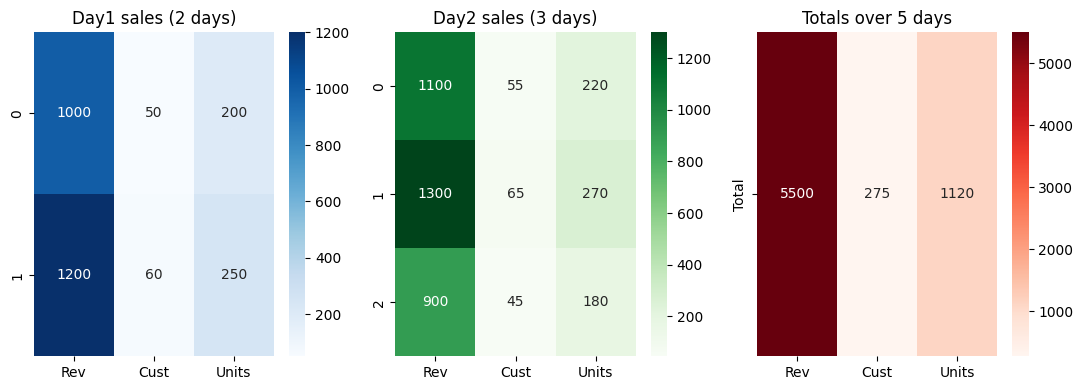

In [5]:
# Step 2.4: Heatmaps (business dashboard style)
plt.figure(figsize=(11, 4))
plt.subplot(1, 3, 1); sns.heatmap(day1_sales, annot=True, fmt='d', cmap='Blues', xticklabels=['Rev', 'Cust', 'Units'])
plt.title('Day1 sales (2 days)')
plt.subplot(1, 3, 2); sns.heatmap(day2_sales, annot=True, fmt='d', cmap='Greens', xticklabels=['Rev', 'Cust', 'Units'])
plt.title('Day2 sales (3 days)')
plt.subplot(1, 3, 3); sns.heatmap(totals.reshape(1, -1), annot=True, fmt='d', cmap='Reds', xticklabels=['Rev', 'Cust', 'Units'], yticklabels=['Total'])
plt.title('Totals over 5 days')
plt.tight_layout(); plt.show()

## A multiplication that means something
**Work out the shapes on paper first.**

| Operation | Shapes | Result shape | Meaning of one entry |
|---|---|---|---|
| `units @ prices` | (3 days × 2 products) @ (2,) | (3,) | revenue of one day |
| `units @ price_cost` | (3 × 2) @ (2 × 2) | (3 × 2) | [revenue, cost] of one day |

The inner dimensions (2 and 2) match and disappear; the outer dimensions (3 and 2) are what is left.

In [6]:
# Step 2.5: Revenue per day = units @ prices
units = np.array([[10, 5],     # day 1: 10 of product A, 5 of product B
                  [ 8, 12],    # day 2
                  [15, 3]])    # day 3        -> shape (3, 2)
prices = np.array([20, 35])    # price of A, price of B -> shape (2,)

revenue_per_day = units @ prices
print("units", units.shape, "@ prices", prices.shape, "->", revenue_per_day.shape)
print("Revenue per day:", revenue_per_day)

units (3, 2) @ prices (2,) -> (3,)
Revenue per day: [375 580 405]


**What this means:** each entry is `units_A × price_A + units_B × price_B` for one day. For day 1: 10×20 + 5×35 = 375. So `units @ prices` is the revenue of each day.

In [7]:
# Step 2.6: Revenue AND cost per day at once = units @ [[price_A, cost_A], [price_B, cost_B]]
price_cost = np.array([[20, 8],     # product A: price 20, cost 8
                       [35, 15]])   # product B: price 35, cost 15   -> shape (2, 2)

rev_cost = units @ price_cost
print("units", units.shape, "@ price_cost", price_cost.shape, "->", rev_cost.shape)
print("[revenue, cost] per day:\n", rev_cost)
print("Profit per day:", rev_cost[:, 0] - rev_cost[:, 1])

units (3, 2) @ price_cost (2, 2) -> (3, 2)
[revenue, cost] per day:
 [[375 155]
 [580 244]
 [405 165]]
Profit per day: [220 336 240]


**What this means:** the first column of the result is the revenue of each day (same as above) and the second column is the cost of each day (`units_A × cost_A + units_B × cost_B`). One multiplication gives two business numbers, and profit is simply the difference.

## Rotation matrices
A real 2D rotation by an angle θ is `R = [[cos θ, -sin θ], [sin θ, cos θ]]`. It turns vectors without changing their length. Mathematically that means R is **orthogonal**: `Rᵀ R = I`.

In [8]:
# Step 2.7: A real rotation matrix (30 degrees) and the orthogonality check
theta = np.radians(30)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])

print("R:\n", R.round(3))
print("R.T @ R == I ?", np.allclose(R.T @ R, np.eye(2)))

R:
 [[ 0.866 -0.5  ]
 [ 0.5    0.866]]
R.T @ R == I ? True


**What this means:** `Rᵀ R` is the identity matrix, so R is orthogonal: it only rotates, it never stretches or shears.

In [9]:
# Step 2.8: The old matrix [[0.9, 0.4], [0.4, 0.9]] is NOT a rotation
M = np.array([[0.9, 0.4], [0.4, 0.9]])

print("M.T @ M:\n", M.T @ M)
print("M.T @ M == I ?", np.allclose(M.T @ M, np.eye(2)))

M.T @ M:
 [[0.97 0.72]
 [0.72 0.97]]
M.T @ M == I ? False


**What this means:** `Mᵀ M` is not the identity, so M is not orthogonal. It stretches and mixes the axes instead of rotating, so calling it a "rotation matrix" was wrong.

In [10]:
# Step 2.9: Does the matrix preserve vector lengths?
features = np.array([[1, 2], [3, 4], [5, 6]])   # 3 samples x 2 features

rotated     = features @ R.T     # rotate each row vector by 30 degrees
transformed = features @ M       # the old matrix

print("Original lengths:", np.linalg.norm(features, axis=1).round(3))
print("After R         :", np.linalg.norm(rotated, axis=1).round(3))
print("After old M     :", np.linalg.norm(transformed, axis=1).round(3))
print("R preserves lengths:", np.allclose(np.linalg.norm(rotated, axis=1), np.linalg.norm(features, axis=1)))
print("M preserves lengths:", np.allclose(np.linalg.norm(transformed, axis=1), np.linalg.norm(features, axis=1)))

Original lengths: [2.236 5.    7.81 ]
After R         : [2.236 5.    7.81 ]
After old M     : [ 2.78   6.444 10.118]
R preserves lengths: True
M preserves lengths: False


**What this means:** multiplying the data by R changes the direction of each sample but keeps its length, because R is orthogonal. The old matrix M makes every sample longer (it is not a rotation), so it distorts the data.
(`features @ R.T` is used because each sample is a *row*; for a single column vector you would write `R @ v`.)
This idea matters for PCA: its principal components form an orthogonal matrix, so projecting onto them rotates the data without distorting distances.

## Key takeaways
- Shapes must be compatible to multiply: `(m×n) @ (n×p) → (m×p)`. `shape[0]` = rows, `shape[1]` = columns
- **Compatible shapes ≠ meaningful result.** Always ask what each entry of the output means (revenue × revenue is meaningless)
- To total tables, `vstack` them and `sum(axis=0)`. To get revenue and cost, multiply units by a price/cost matrix
- `np.dot` and the `@` operator give the same result for matrices
- A true rotation matrix is orthogonal (`Rᵀ R = I`) and preserves lengths. A random-looking matrix like `[[0.9, 0.4], [0.4, 0.9]]` is not a rotation
- Multiplying data by a matrix **transforms features**. This is the step PCA relies on